# masked clade comparison file

In [123]:
import tskit
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, SVG

In [124]:
# functions
def clade_membership(tree, *, include_singletons=True, include_root=True):
    sample_ids = tree.tree_sequence.samples()
    column = {int(s): j for j, s in enumerate(sample_ids)}

    node_ids = np.array([
        u for u in tree.nodes(order="postorder")
        if (include_singletons or tree.num_samples(u) >= 2)
        and (include_root or not tree.is_root(u))
    ], dtype=np.int32)

    membership = np.zeros(
        (len(node_ids), len(sample_ids)), dtype=np.uint8
    )

    for i, u in enumerate(node_ids):
        columns = [column[s] for s in tree.samples(int(u))]
        membership[i, columns] = 1

    return node_ids, sample_ids, membership


In [125]:

def correlate_clades(membership, carrier):
    X = np.asarray(membership, dtype=float)
    y = np.asarray(carrier, dtype=float)

    if X.ndim != 2 or y.shape != (X.shape[1],):
        raise ValueError("Provide one carrier value per membership column.")
    if not np.isin(X, [0, 1]).all() or not np.isin(y, [0, 1]).all():
        raise ValueError("Membership and carrier arrays must contain only 0 and 1.")

    X_centered = X - X.mean(axis=1, keepdims=True)
    y_centered = y - y.mean()

    if np.linalg.norm(y_centered) == 0:
        raise ValueError("Carrier array must contain both carriers and non-carriers.")

    denominator = (
        np.linalg.norm(X_centered, axis=1)
        * np.linalg.norm(y_centered)
    )

    correlations = np.full(X.shape[0], np.nan)
    np.divide(
        X_centered @ y_centered,
        denominator,
        out=correlations,
        where=denominator > 0,
    )
    return correlations

In [ ]:
# Load the tree sequences

filename = "chr12_HapMapII_GRCh37_CEU50_seed1"
percent = "5"

# reference ts from stdpopsim
ts_std = tskit.load(f"../stdpopsim_simulations/simulations/{filename}.trees")
# masked ts from Relate
ts_masked = tskit.load(f"../Relate_sims/masked_{filename}_{percent}.00percent_20bins_seed42.trees")

# load in hidden SNP indices
hidden_snps_df = pd.read_csv(f"../Relate_sims/hidden_snps_key_{filename}_{percent}.00percent_20bins_seed42.csv")

# load in the full .hapsfile
path = f"../Relate_sims/data/{filename}.haps"

# # format the haps file into a pandas dataframe
# haps_df = pd.read_csv(path, sep=r"\s+", header=None)

# haps_df = haps_df.rename(columns={
#     0: "Chromosome number",
#     1: "SNP ID",
#     2: "SNP position",
#     3: "Ancestral allele",
#     4: "Alternative allele",
# })


In [127]:
hidden_snps_df

,Unnamed: 0,Chromosome number,SNP ID,SNP position,Ancestral allele,Alternative allele,5,6,7,8,...,97,98,99,100,101,102,103,104,ALT_count,ALT_count_numbered_bin
0,212788,12,212954,120911507,G,A,1,0,0,0,...,0,0,0,0,1,0,0,1,6,1
1,44920,12,44951,26120427,A,C,0,0,0,0,...,0,0,0,0,0,0,0,0,13,2
2,221142,12,221311,125930344,A,G,0,0,0,0,...,0,0,0,0,0,0,0,0,5,0
3,175218,12,175349,99018621,C,G,0,0,0,0,...,0,1,0,0,0,1,0,0,36,7
4,111978,12,112063,64752470,G,T,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23440,63559,12,63601,37507465,G,C,1,1,0,0,...,0,0,0,1,0,0,0,0,19,3
23441,16254,12,16270,9207601,T,G,0,0,0,0,...,0,0,0,0,0,0,1,0,12,2
23442,126249,12,126345,72419579,G,A,0,0,0,0,...,0,0,0,0,1,0,0,0,3,0
23443,109581,12,109665,63538777,A,G,1,1,1,0,...,1,1,1,1,1,1,0,0,66,13


## run loop

In [141]:
correlation_record = []
positions = hidden_snps_df["SNP position"].to_numpy()
carrier_columns = [str(i) for i in range(5, 105)]

for idx, snp_pos in enumerate(positions):
    row = hidden_snps_df.iloc[idx]
    current_masked_tree = ts_masked.at(snp_pos)
    carrier_indvs_ref = row[carrier_columns].to_numpy(dtype=int)

    node_ids, sample_ids, membership = clade_membership(
        current_masked_tree,
        include_singletons=True,
        include_root=True,
    )

    correlations = correlate_clades(membership, carrier_indvs_ref)

    if not np.isfinite(correlations).any():
        raise ValueError(f"No defined correlations at position {snp_pos}.")

    best_index = np.nanargmax(correlations)
    max_corr = correlations[best_index]

    correlation_record.append({
        "SNP position": snp_pos,
        "max_corr": max_corr,
        "ALT_count": row["ALT_count"],
        "ALT_bin_num": row["ALT_count_numbered_bin"],
    })

results = pd.DataFrame(correlation_record)

In [214]:
results

,SNP position,max_corr,ALT_count,ALT_bin_num
0,120911507,1.000000,6,1
1,26120427,1.000000,13,2
2,125930344,0.908054,5,0
3,99018621,0.956987,36,7
4,64752470,1.000000,1,0
...,...,...,...,...
23440,37507465,1.000000,19,3
23441,9207601,1.000000,12,2
23442,72419579,1.000000,3,0
23443,63538777,0.977805,66,13


In [215]:
results.to_csv(f"{filename}_{percent}.00percent_20bins_seed42_results.csv", index=False)

## look at individual snp, and clade membership comparison

In [197]:
positions = np.array(hidden_snps_df["SNP position"])
positions

array([120911507,  26120427, 125930344, ...,  72419579,  63538777,
        77922914], shape=(23445,))

In [198]:
# inspecting index
idx = 2

In [199]:

# Compare the trees at one SNP (change row_idx to inspect another).
position = positions[idx]  # Change this index to inspect a different SNP
tree_std, tree_masked = ts_std.at(position), ts_masked.at(position)

print(f"SNP position: {position}")
print(f"Reference tree interval: {tree_std.interval}")
print(f"Reference tree index: {tree_std.index}")
print(f"Reference tree number of nodes: {tree_std.num_nodes} \n")

print(f"Masked tree interval:    {tree_masked.interval}")
print(f"Masked tree index:    {tree_masked.index}")
print(f"Masked tree number of nodes:    {tree_masked.num_nodes}")

SNP position: 125930344
Reference tree interval: Interval(left=125928480.0, right=125931508.0)
Reference tree index: 175939
Reference tree number of nodes: 123384 

Masked tree interval:    Interval(left=125920619.5, right=125955263.5)
Masked tree index:    12220
Masked tree number of nodes:    1336006


/Users/sofiamedina/miniforge3/envs/ts_stuff/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3762: FutureWarning: This property is a deprecated alias for Tree.tree_sequence.num_nodes and will be removed in the future. To obtain the number of nodes in the topology of the current tree (i.e. reachable from the roots) use len(tree.preorder()).
  if await self.run_code(code, result, async_=asy):


In [200]:
hidden_snps_df.head(5)

,Unnamed: 0,Chromosome number,SNP ID,SNP position,Ancestral allele,Alternative allele,5,6,7,8,...,97,98,99,100,101,102,103,104,ALT_count,ALT_count_numbered_bin
0,212788,12,212954,120911507,G,A,1,0,0,0,...,0,0,0,0,1,0,0,1,6,1
1,44920,12,44951,26120427,A,C,0,0,0,0,...,0,0,0,0,0,0,0,0,13,2
2,221142,12,221311,125930344,A,G,0,0,0,0,...,0,0,0,0,0,0,0,0,5,0
3,175218,12,175349,99018621,C,G,0,0,0,0,...,0,1,0,0,0,1,0,0,36,7
4,111978,12,112063,64752470,G,T,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0


In [205]:
row = hidden_snps_df.iloc[idx]
masked_carrier = row[[str(i) for i in range(5, 105)]].to_numpy(dtype=int)

node_ids, sample_ids, membership = clade_membership(
    tree_masked, include_singletons=True, include_root=True
)
print(masked_carrier)


[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0
 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [207]:

correlations = correlate_clades(membership, masked_carrier)
best_index = np.nanargmax(correlations)
best_array = membership[best_index]

print("SNP position:", position)
print("Tree interval:", tree_masked.interval)
print("Maximum correlation:", correlations[best_index])

print("True allele:    ", masked_carrier)
print("Best matching clade:  ", best_array)
print("\n Mismatch (1=yes):", (masked_carrier != best_array).astype(int))

SNP position: 125930344
Tree interval: Interval(left=125920619.5, right=125955263.5)
Maximum correlation: 0.9080536347093006
True allele:     [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0
 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Best matching clade:   [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0
 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0]

 Mismatch (1=yes): [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0]


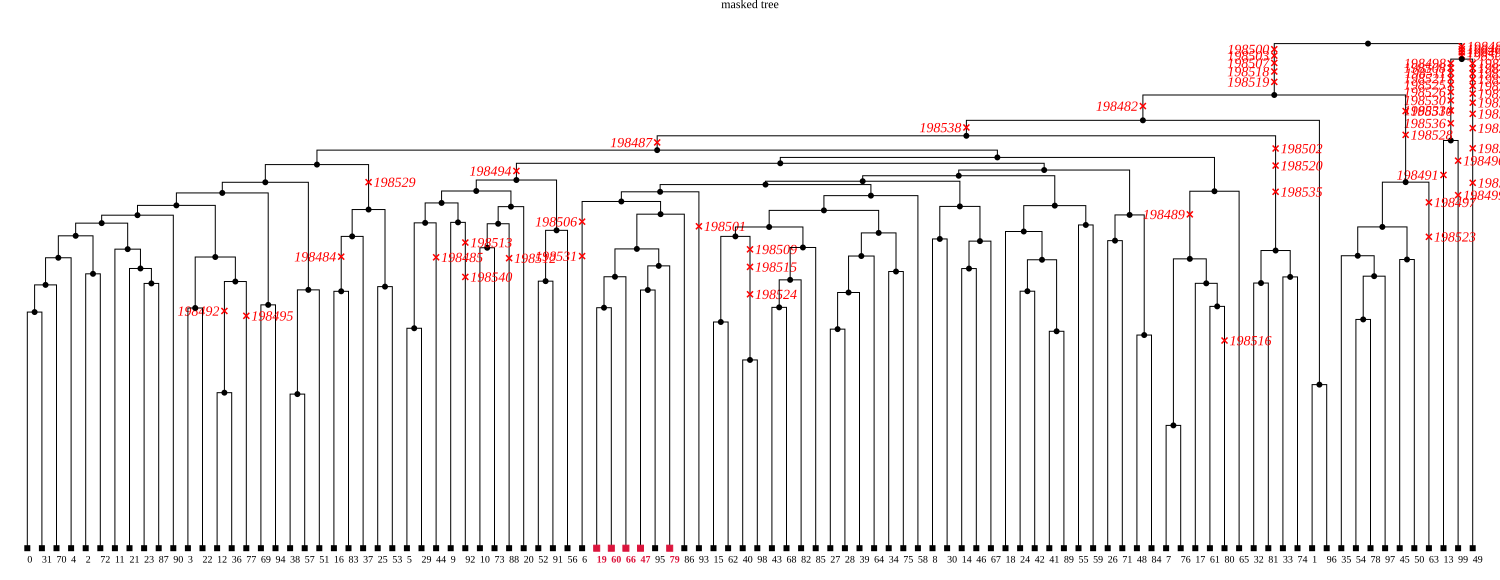

In [211]:
# nicer formatting for a larger tree
wide_fmt = (1500, 580)
# Create a stylesheet that shrinks labels and rotates leaf labels, to avoid overlap
node_label_style = (
    ".node > .lab {font-size: 80%}"
    ".leaf > .lab {text-anchor: start; transform: rotate(90deg) translate(6px)}"
)

carrier_nodes = sample_ids[masked_carrier == 1]
node_labels = {int(u): str(u) for u in ts_masked.samples()}

style = """
.leaf > .lab {font-size: 10px;}
"""

for node in carrier_nodes:
    style += f"""
    .node.n{int(node)} > .sym {{fill: crimson; stroke: crimson;}}
    .node.n{int(node)} > .lab {{fill: crimson; font-weight: bold;}}
    """

display(SVG(tree_masked.draw_svg(
    title= "masked tree",
    size=wide_fmt,
    node_labels=node_labels,
    time_scale="log_time",
    style=node_label_style + style,
    
)))

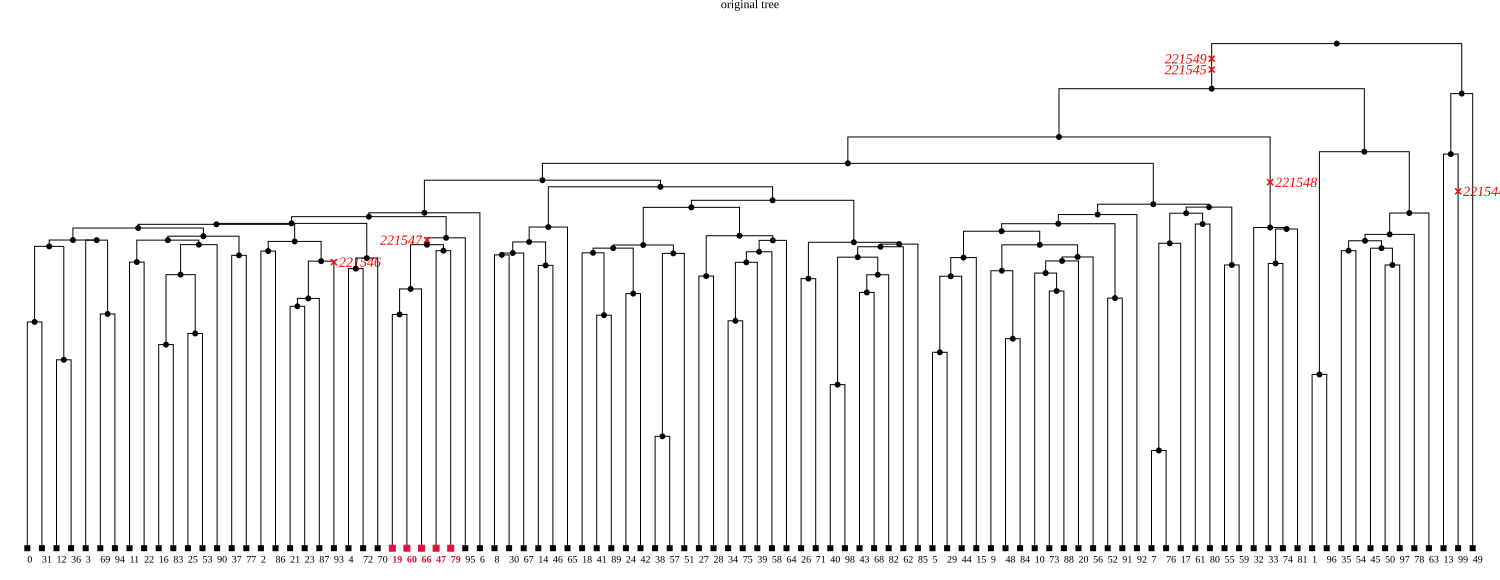

In [212]:
display(SVG(tree_std.draw_svg(
    title= "original tree",
    size=wide_fmt,
    node_labels=node_labels,
    time_scale="log_time",
    style=node_label_style + style,
    
)))

In [170]:
membership[0]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=uint8)

In [196]:
node_ids

array([ 2,  0,  1,  6,  7,  5,  3,  4,  8,  9, 10], dtype=int32)

In [172]:
len(node_ids)

199

In [182]:
tables = tskit.TableCollection(sequence_length=1)

# Sample nodes: 0=A, 1=B, 2=C, 3=D, 4=E, 5=F
for _ in range(6):
    tables.nodes.add_row(flags=tskit.NODE_IS_SAMPLE, time=0)

# Internal nodes 6–10
for time in (1, 2, 1, 2, 3):
    tables.nodes.add_row(time=time)

# (((A, B), C), ((D, E), F))
for parent, child in [
    (6, 0), (6, 1),
    (7, 6), (7, 2),
    (8, 3), (8, 4),
    (9, 8), (9, 5),
    (10, 7), (10, 9),
]:
    tables.edges.add_row(left=0, right=1, parent=parent, child=child)

# One site: ancestral G; A arises above A/B, C above D/E.
site = tables.sites.add_row(position=0.5, ancestral_state="G")
tables.mutations.add_row(site=site, node=6, derived_state="A")
tables.mutations.add_row(site=site, node=8, derived_state="C")

tables.sort()
ts = tables.tree_sequence()
tree = ts.first()

labels = {
    0: "0: A (A)", 1: "1: B (A)", 2: "2: C (G)",
    3: "3: D (C)", 4: "4: E (C)", 5: "5: F (G)",
    6: "6", 7: "7", 8: "8", 9: "9", 10: "10",
}


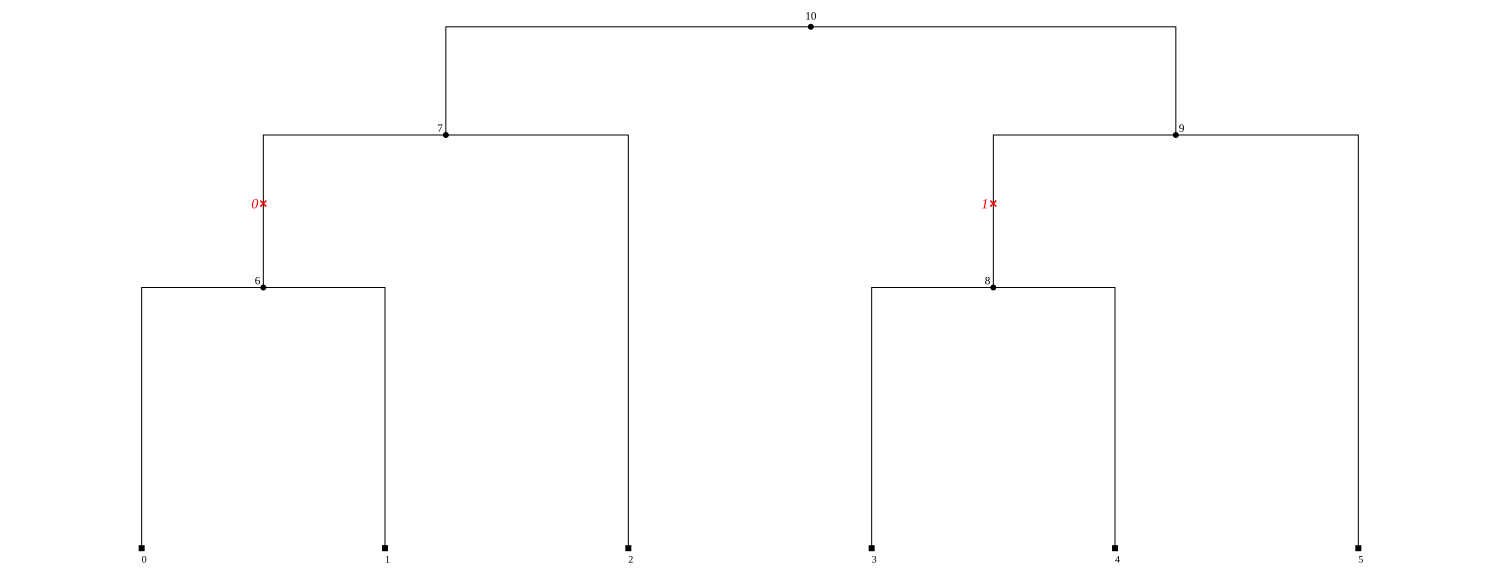

In [183]:
display(SVG(tree.draw_svg(
    size=wide_fmt,
    node_labels=node_labels,
    time_scale="log_time",
    style=node_label_style + style,
    
)))

In [195]:
node_ids, sample_ids, membership = clade_membership(
    tree, include_singletons=True, include_root=True
)
print("Clade membership is in this node order: ", node_ids)
print("\n", membership)

Clade membership is in this node order:  [ 2  0  1  6  7  5  3  4  8  9 10]

 [[0 0 1 0 0 0]
 [1 0 0 0 0 0]
 [0 1 0 0 0 0]
 [1 1 0 0 0 0]
 [1 1 1 0 0 0]
 [0 0 0 0 0 1]
 [0 0 0 1 0 0]
 [0 0 0 0 1 0]
 [0 0 0 1 1 0]
 [0 0 0 1 1 1]
 [1 1 1 1 1 1]]


In [188]:
membership[0]

array([0, 0, 1, 0, 0, 0], dtype=uint8)

In [194]:
node_ids, sample_ids, membership = clade_membership(
    tree, include_singletons=True, include_root=True
)

sample_names = dict(zip(sample_ids, "ABCDEF"))

print("         A B C D E F")
for node, row in sorted(zip(node_ids, membership)):
    members = [sample_names[s] for s, present in zip(sample_ids, row) if present]
    bits = " ".join(map(str, row))
    print(f"node {node:2}: {bits}   {{{', '.join(members)}}}")

         A B C D E F
node  0: 1 0 0 0 0 0   {A}
node  1: 0 1 0 0 0 0   {B}
node  2: 0 0 1 0 0 0   {C}
node  3: 0 0 0 1 0 0   {D}
node  4: 0 0 0 0 1 0   {E}
node  5: 0 0 0 0 0 1   {F}
node  6: 1 1 0 0 0 0   {A, B}
node  7: 1 1 1 0 0 0   {A, B, C}
node  8: 0 0 0 1 1 0   {D, E}
node  9: 0 0 0 1 1 1   {D, E, F}
node 10: 1 1 1 1 1 1   {A, B, C, D, E, F}
